In [2]:
import numpy as np
import matplotlib.pyplot as plt

## Brownian Motion

Brownian Motion is a stochastic process $\{W_t\}_{t \in [0,T]}$ - A collection of random variables $W_t$, one for every time t between 0 and 1. 

Define $W : [0,T] \times \Omega \to \mathbb{R}$, where:
- $W_0$ = 0
- W has independent increments
- W has Guassian (normal) increments
- W has continuous sample paths. 

#### Simple Symmetric Random Walks

A simple symmetric random walk is formed with independent steps $X_i \in \{-1,1\}$, with $P(X_i=1)=P(X_i=-1)=\frac{1}{2}$. 

The position of the walk after n steps is $S_n=\sum{i=1}^{n}X_i$. Each simulated path shows one possible sequence of random +1 and -1 movements over time. 

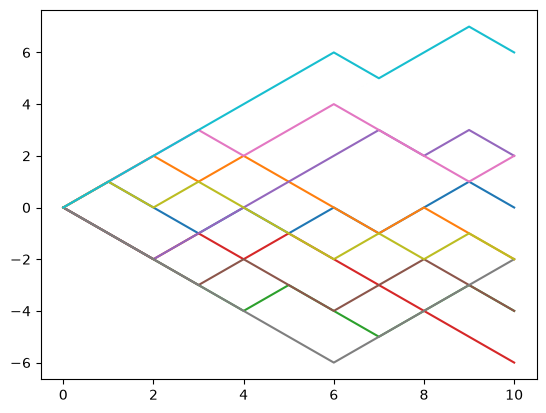

In [127]:
M = 10
t = 10
t_array = np.arange(0, t+1)

for i in range(M):

    steps = np.random.choice([1,-1], t)
    path = np.concatenate(([0], np.cumsum(steps)))

    plt.plot(t_array, path)

plt.show()

#### Scaled Symmetric Random Walk

A simple symmetric random walk takes steps of +1 or -1 with equal probability. To approximate Brownian motion over a fixed interval [0,T], divide time into n intervals of length $\Delta t = \frac{T}{n}$. The step size is scaled to $\sqrt{\Delta t}$, to preserve right amount of randomness. Thus $\Delta X_i = +\sqrt{\Delta t}$, with probability 1/2, and $-\sqrt{\Delta t}$, with probability 1/2. 

As n increases, the time intervals and jump sizes shrink; the scaled random walk more closely resembles Brownian Motion. 

<function matplotlib.pyplot.show(close=None, block=None)>

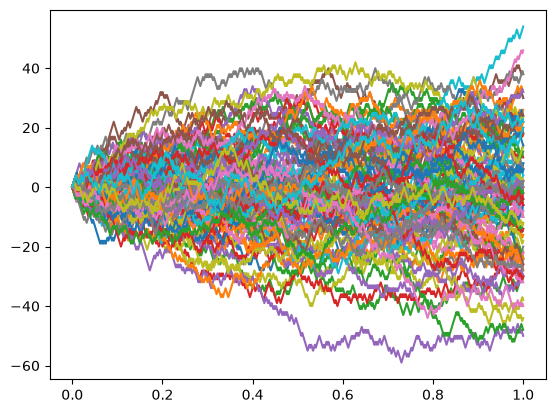

In [128]:
M = 100
T = 1
n = 500
t_array = np.linspace(0, T, n+1)

for i in range(M):

    steps = np.random.choice([1,-1], n)
    scaled_steps = 1/np.sqrt(n) * steps

    path = np.concatenate(([0], np.cumsum(steps)))

    plt.plot(t_array, path)

plt.show


#### Discrete Simulation of Brownian Motion

Brownian motion has independent increments satisfying $\Delta W \sim N(0,\Delta t)$. A discrete Brownian path can be simulated by generating n independent Guassian increments with std. = $\sqrt{\Delta t}$, then cumulatively summing values from $W_0 = 0$. 

This produces values of Brownian Motion at the discrete times $0,\Delta t,2\Delta t,\ldots,T.$

<function matplotlib.pyplot.show(close=None, block=None)>

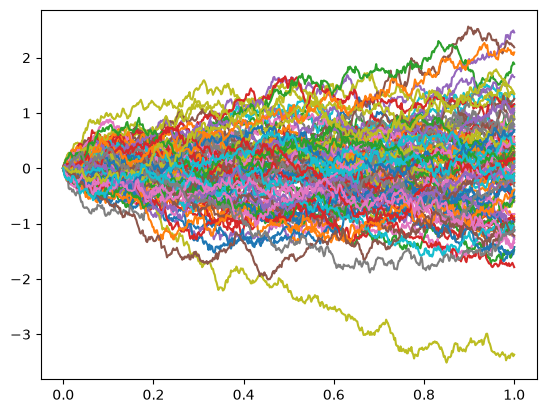

In [129]:
M = 100
T = 1
n = 500
t_array = np.linspace(0, T, n+1)

for i in range(M):

    steps = np.random.normal(0, np.sqrt(T/n), n)
    path = np.concatenate(([0], np.cumsum(steps)))

    plt.plot(t_array, path)

plt.show

#### Discrete Simulation of Drifted Brownian Motion

<function matplotlib.pyplot.show(close=None, block=None)>

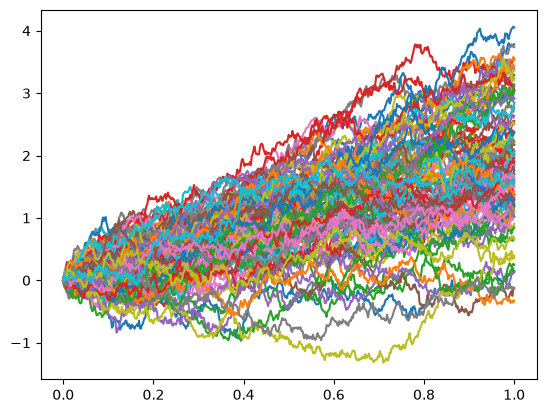

In [130]:
mu = 2
sigma = 1

M = 100
T = 1
n = 500
t_array = np.linspace(0, T, n+1)

delta_t = T/n

for i in range(M):

    steps = np.random.normal(mu * delta_t, sigma * np.sqrt(delta_t), n)
    path = np.concatenate(([0], np.cumsum(steps)))

    plt.plot(t_array, path)

plt.show

## Itô's Lemma

For ordinary differentiable processes, increments over small intervals are of order $dt$, so terms such as $(dt)^2$ vanish in the Taylor expansion.
Brownian motion behaves differently; its increments scale as

$$
dW_t \sim \sqrt{dt}
\quad \Longrightarrow \quad
(dW_t)^2 \sim dt.
$$

So the second-order term involving Brownian motion, $(dW_t)^2$, can't be ignored.

In differential notation, this gives the standard Itô multiplication rules:

$$
(dW_t)^2 = dt, \qquad dW_t\,dt = 0, \qquad (dt)^2 = 0.
$$

For a function $f(t,X_t)$, once differentiable in time, twice differentiable in $X_t$, a second-order Taylor expansion together with the Itô rules gives

$$
\begin{aligned}
f(t+\Delta t,x+\Delta x)
\approx\;&
f(t,x)
+
\frac{\partial f}{\partial t}\Delta t
+
\frac{\partial f}{\partial x}\Delta x \\
&+
\frac{1}{2}
\left[
\frac{\partial^2 f}{\partial t^2}(\Delta t)^2
+
2\frac{\partial^2 f}{\partial t\,\partial x}\Delta t\,\Delta x
+
\frac{\partial^2 f}{\partial x^2}(\Delta x)^2
\right].
\end{aligned}
$$

The relevant terms reduce to
$$
df
=
\frac{\partial f}{\partial t}\,dt
+
\frac{\partial f}{\partial x}\,dX_t
+
\frac{1}{2}
\frac{\partial^2 f}{\partial x^2}(dX_t)^2.
$$

Now consider a general Itô process, 

$$dX_t = a(t,X_t)\,dt + b(t,X_t)\,dW_t$$

Using the Itô multiplication rules,

$$
(dX_t)^2
=
b^2(t,X_t)\,dt.
$$

Substituting and collecting the $dt$ and $dW_t$ terms gives

$$
df(t,X_t)
=
\left[
\frac{\partial f}{\partial t}
+
a(t,X_t)\frac{\partial f}{\partial x}
+
\frac{1}{2}b^2(t,X_t)\frac{\partial^2 f}{\partial x^2}
\right]dt
+
b(t,X_t)\frac{\partial f}{\partial x}\,dW_t.
$$

This is Itô's lemma for a general Itô process. The additional term

$$
\frac{1}{2}
b^2(t,X_t)
\frac{\partial^2 f}{\partial x^2}
\,dt
$$

Arises from the quadratic variation of Brownian motion. It captures the interaction between volatility of $X_t$ and curvature of $f$. This is used to transform geometric Brownian motion. Later, this result becomes key to deriving the Black-Scholes equation.





## Geometric Brownian Motion

Let $\{P_t\}_{t \geq 0}$ denote a stochastic process representing the price of an asset. Assume that $P_t$ is an Itô process of the form

$$
dP_t = a(t,P_t)\,dt + b(t,P_t)\,dB_t.
$$

Geometric Brownian motion is obtained by choosing the drift and diffusion coefficients to be proportional to the current asset price:

$$
a(t,P_t)=\mu P_t,
\qquad
b(t,P_t)=\sigma P_t.
$$

Where $\mu$ is the drift rate and $\sigma$ is the volatility. 

Hence,

$$
dP_t = \mu P_t\,dt + \sigma P_t\,dB_t.
$$
Since both terms are multiplied by $P_t$, the magnitude of both the expected price and random price changes scales with the current asset price.
To obtain the dynamics of the log price, define:

$$
f(P_t)=\ln P_t.
$$

Since $f$ has no explicit dependence on time, we obtain:

$$
\frac{\partial f}{\partial t}=0,
\qquad
\frac{\partial f}{\partial P}
=
\frac{1}{P_t},
\qquad
\frac{\partial^2 f}{\partial P^2}
=
-\frac{1}{P_t^2}.
$$

Applying Itô's lemma,

$$
df
=
\left[
a(t,P_t)\frac{\partial f}{\partial P}
+
\frac{1}{2}b^2(t,P_t)\frac{\partial^2 f}{\partial P^2}
\right]dt
+
b(t,P_t)\frac{\partial f}{\partial P}\,dB_t.
$$

Substituting $a(t,P_t)=\mu P_t, b(t,P_t)=\sigma P_t$ gives:

$$
d\ln P_t
=
\left[
\mu P_t\left(\frac{1}{P_t}\right)
+
\frac{1}{2}\sigma^2P_t^2
\left(-\frac{1}{P_t^2}\right)
\right]dt
+
\sigma P_t\left(\frac{1}{P_t}\right)dB_t.
$$

$$
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)dt
+
\sigma\,dB_t.
$$

Taking logarithms transforms the multiplicative dynamics of GBM into the additive dynamics of Brownian motion with drift. Note Brownian motion with drift has a known normal distribution, allowing the distribution and exact solution of $P_t$ to be derived.

Integrating from $0$ to $t$ gives:

$$
\ln P_t-\ln P_0
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t

\Longleftrightarrow

\ln\left(\frac{P_t}{P_0}\right)
=
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t
$$

Exponentiating both sides and rearranging:

$$
P_t
=
P_0
\exp\left[
\left(
\mu-\frac{1}{2}\sigma^2
\right)t
+
\sigma B_t
\right].
$$

This is the exact solution of geometric Brownian motion. Since the exponential function is always positive, $P_t>0$ whenever $P_0>0$.


## Single Path Geometric Brownian Motion Simulation

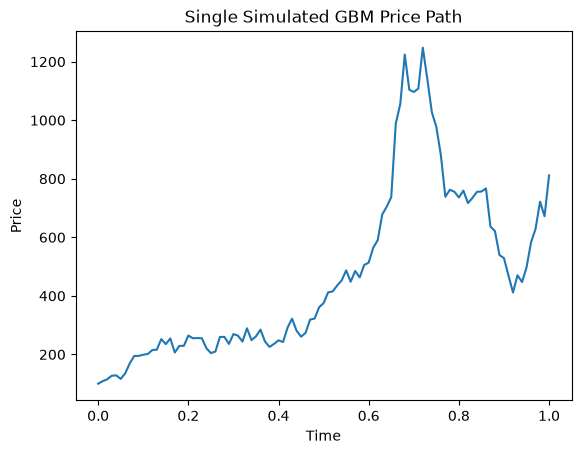

In [139]:
P0 = 100
mu = 1
sigma = 1
T = 1
n = 100
t_array = np.linspace(0, T, n+1)
brownian_array = [0]
price_path = [P0]

delta_t = T/n



for i in range(1, n+1):


    brownian_array.append(brownian_array[-1] + np.random.normal(0, np.sqrt(delta_t)))
    price = P0 * np.exp((mu - 0.5 * (sigma ** 2)) * t_array[i] + sigma * brownian_array[-1])
    price_path.append(price)

plt.plot(t_array, price_path)
plt.xlabel("Time")
plt.ylabel("Price")
plt.title("Single Simulated GBM Price Path")
plt.show()
                             

The path above represents one possible realization of an asset price following geometric Brownian motion. Repeating the simulation generates a different path while preserving the same drift and volatility parameters.

## Monte Carlo Simulation

In [9]:
# parameters

P0 = 100
mu = 0.08
sigma = 0.20

M = 1000000
T = 1
n = 100

t_array = np.linspace(0, T, n+1)
delta_t = T/n

**Baseline: Nested Python Loops**

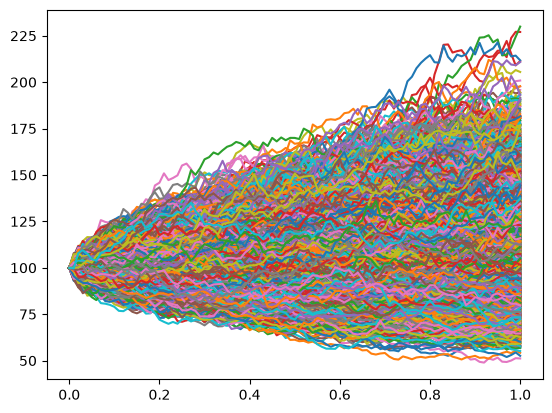

In [134]:
for path in range(M):

    brownian_array = [0]
    price_path = [P0]

    for i in range(1, n+1):


        brownian_array.append(brownian_array[-1] + np.random.normal(0, np.sqrt(delta_t)))
        price = P0 * np.exp((mu - 0.5 * (sigma ** 2)) * t_array[i] + sigma * brownian_array[-1])
        price_path.append(price)

    plt.plot(t_array, price_path)

plt.show()

**Fully Vectorised Simulation**

In [10]:
randoms = np.random.normal(0, np.sqrt(delta_t), size=(M, n))
zeros = np.array([[0]] * M)

brownian_increments = np.concatenate((zeros, randoms), axis = 1)
brownian = np.cumsum(brownian_increments, axis = 1)

diffusion = np.multiply(sigma, brownian)
drift = np.multiply(t_array, (mu - 0.5 * (sigma**2)))

price_factor = np.exp(drift + diffusion)
prices = np.multiply(P0, price_factor)

transposed_prices = prices.T

<function matplotlib.pyplot.show(close=None, block=None)>

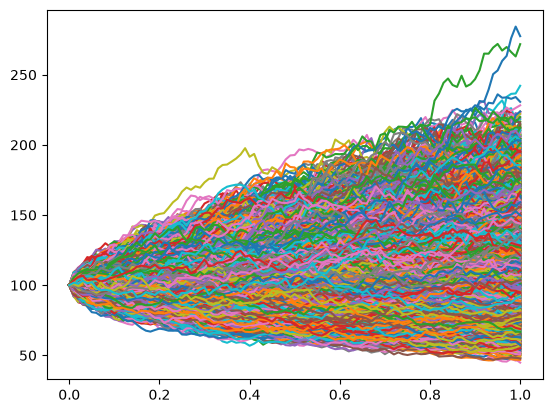

In [151]:
plt.plot(t_array, transposed_prices)
plt.show

The simulated paths show different possible evolutions of an asset price under geometric Brownian motion. All paths share the same drift and volatility parameters but differ because of their independent Brownian shocks. The dispersion between paths increases over time, reflecting the accumulation of uncertainty.

| Implementation | Runtime (ms) |
|---|---:|
| Nested Python loops | 1111 |
| Vectorised over time | 85.9 |
| Fully vectorised | 30.9 |

Vectorising the simulation reduced runtime from approximately 1.11 s to 30.9 ms for 10,000 paths, a speedup of roughly 36×

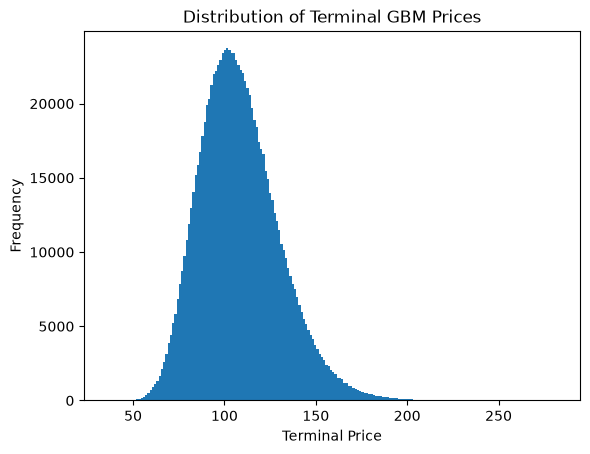

In [14]:
terminal_prices = prices[:,-1]

plt.hist(terminal_prices,
        bins = 200
         )

plt.xlabel("Terminal Price")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal GBM Prices")

plt.show()

In [ ]:
simulated_mean = np.mean(terminal_prices)
simulated_variance = np.var(terminal_prices)

theoretical_mean = P0 * np.exp(mu * T)
theoretical_variance = P0**2 * np.exp(2 * mu * T) * (np.exp(sigma**2 * T) - 1)

print("Terminal Prices")
print(f"Simulated mean:       {simulated_mean:.4f}")
print(f"Theoretical mean:     {theoretical_mean:.4f}")
print(f"Simulated variance:   {simulated_variance:.4f}")
print(f"Theoretical variance: {theoretical_variance:.4f}")

Terminal Prices
Simulated mean:       108.3365
Theoretical mean:     108.3287
Simulated variance:   478.6902
Theoretical variance: 478.9189


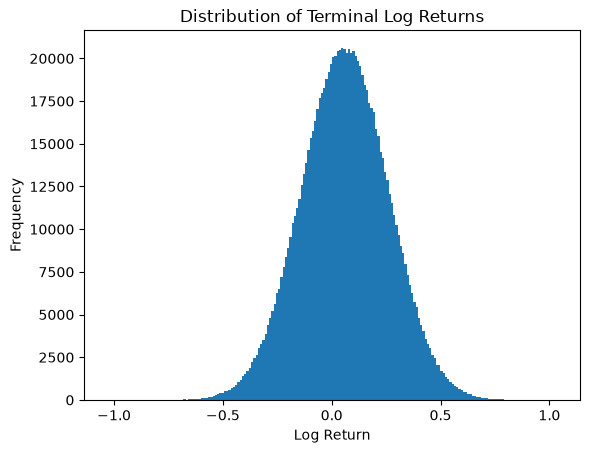

In [24]:
terminal_factors = np.divide(terminal_prices, P0)

log_returns = np.log(terminal_factors)

plt.hist(log_returns,
        bins = 200
         )

plt.xlabel("Log Return")
plt.ylabel("Frequency")
plt.title("Distribution of Terminal Log Returns")

plt.show()

In [ ]:
simulated_log_mean = np.mean(log_returns)
simulated_log_var = np.var(log_returns)

theoretical_log_mean = (mu - 0.5 * (sigma**2)) * T
theoretical_log_variance = sigma**2 * T

print("Terminal Prices")
print(f"Simulated mean:       {simulated_log_mean:.4f}")
print(f"Theoretical mean:     {simulated_log_var:.4f}")
print(f"Simulated variance:   {theoretical_log_mean:.4f}")
print(f"Theoretical variance: {theoretical_log_variance:.4f}")

Terminal Prices
Simulated mean:       0.0601
Theoretical mean:     0.0400
Simulated variance:   0.0600
Theoretical variance: 0.0400


### Simulation Validation

The Monte Carlo simulation closely reproduces the theoretical properties of geometric Brownian motion. The simulated mean and variance of the terminal prices closely match their theoretical values and the terminal-price distribution is positively skewed as expected under a lognormal model.

The simulated log returns are approximately normally distributed, with their mean and variance also closely matching the theoretical values. Overall, the simulation provides a numerical validation of the geometric Brownian motion model.